# COU 07506 DIGITAL SIGNAL PROCESSING

## WEEK 4: Z-TRANSFORM LABORATORY — POLES, ZEROS AND STABILITY

**Name:** RAHMA ABDALLAH VUMBI

**Registration Number:** 250242499374

**Class:** BENG24COE-3


---


##  Pre-Lab Preparation

### Question (a)

Find the poles of:

H(z) = 1 / (1 - 0.9z^-1 + 0.81z^-2)

Determine whether the system is stable.

**Solution:**

The denominator is:

z² - 0.9z + 0.81 = 0

Using the quadratic formula:

z = (0.9 ± √(0.81 - 3.24)) / 2

The poles are approximately:

p1 = 0.45 + 0.7794j

p2 = 0.45 - 0.7794j

The magnitude of each pole is approximately 0.9.

Since both poles have magnitudes less than 1, the system is stable.

### Question (b)

Write the partial-fraction expansion of:

X(z) = 1 / [(1 - 0.5z^-1)(1 - 0.25z^-1)]

**Solution:**

Assume:

X(z) = A/(1 - 0.5z^-1) + B/(1 - 0.25z^-1)

After solving for the constants:

A = 2

B = -1

Therefore:

X(z) = 2/(1 - 0.5z^-1) - 1/(1 - 0.25z^-1)

This is the required partial-fraction expansion.

In [1]:
# ==========================================
# WEEK 4: IMPORTING REQUIRED LIBRARIES
# ==========================================

import numpy as np
import matplotlib.pyplot as plt

from scipy import signal

from IPython.display import Audio, display

print("Libraries imported successfully!")

Libraries imported successfully!


## TASK 4.1 — A Pole-Zero Plotting Function

### Objective

To create a Python function that calculates and plots the poles and zeros of a transfer function.

### Background

A transfer function is represented as H(z) = B(z)/A(z).

- Zeros are the roots of the numerator polynomial B(z).
- Poles are the roots of the denominator polynomial A(z).
- A causal system is stable when all its poles are inside the unit circle, meaning their magnitudes are less than 1.

The unit circle is used to determine the position of poles and zeros in the Z-plane.

### Procedure

1. Define a function called zplane.
2. Use SciPy's tf2zpk function to calculate poles and zeros.
3. Plot the unit circle.
4. Plot the zeros using circular markers.
5. Plot the poles using cross markers.
6. Calculate and plot the frequency response.
7. Determine whether the system is stable.

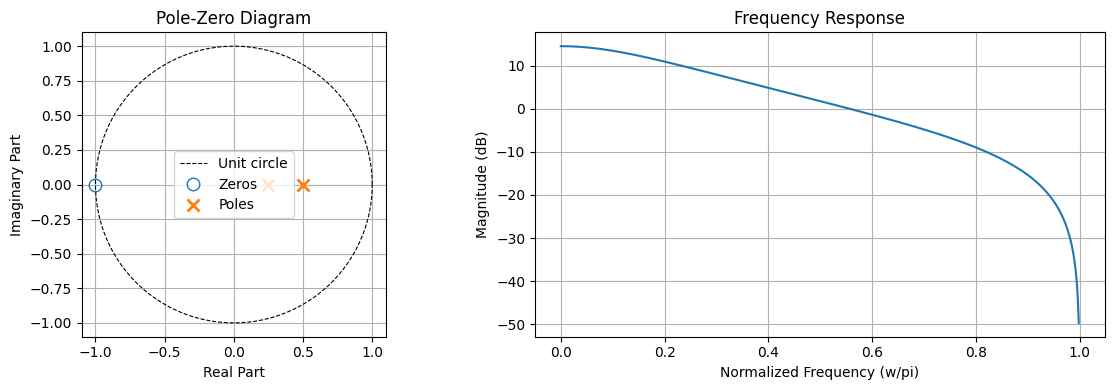

Zeros: [-1.]
Poles: [0.5  0.25]
Is the system stable? True


In [2]:
# ==========================================
# TASK 4.1: POLE-ZERO PLOTTING FUNCTION
# ==========================================

def zplane(b, a, ax=None):

    z, p, k = signal.tf2zpk(b, a)

    if ax is None:
        ax = plt.gca()

    # Create unit circle
    theta = np.linspace(0, 2*np.pi, 400)

    ax.plot(
        np.cos(theta),
        np.sin(theta),
        "k--",
        linewidth=0.8,
        label="Unit circle"
    )

    # Plot zeros
    ax.plot(
        z.real,
        z.imag,
        "o",
        markerfacecolor="none",
        markersize=9,
        label="Zeros"
    )

    # Plot poles
    ax.plot(
        p.real,
        p.imag,
        "x",
        markersize=9,
        markeredgewidth=2,
        label="Poles"
    )

    ax.set_aspect("equal")
    ax.legend()
    ax.set_xlabel("Real Part")
    ax.set_ylabel("Imaginary Part")
    ax.grid()

    return z, p


# Define transfer function
b = [1, 1]
a = [1, -0.75, 0.125]

# Create two plots
fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(12, 4)
)

# Plot pole-zero diagram
z, p = zplane(b, a, ax1)

ax1.set_title("Pole-Zero Diagram")

# Calculate frequency response
w, H = signal.freqz(b, a, worN=512)

# Plot frequency response
ax2.plot(
    w/np.pi,
    20*np.log10(np.maximum(np.abs(H), 1e-12))
)

ax2.set_title("Frequency Response")
ax2.set_xlabel("Normalized Frequency (w/pi)")
ax2.set_ylabel("Magnitude (dB)")
ax2.grid()

plt.tight_layout()
plt.show()

# Check stability
print("Zeros:", z)
print("Poles:", p)

stable = np.all(np.abs(p) < 1)

print("Is the system stable?", stable)

### Observation

The pole-zero diagram shows the positions of poles and zeros in the Z-plane. The unit circle provides a reference for determining stability.

The frequency response shows how the system responds to different frequencies.

Since all poles are inside the unit circle, the system is stable.

## TASK 4.2 — Inverse Z-Transform with residuez

### Objective

To obtain the inverse Z-transform using partial-fraction expansion and verify the result using SciPy's lfilter function.

### Background

The inverse Z-transform converts a function in the Z-domain into a discrete-time sequence in the time domain.

The residuez function calculates the residues, poles and direct terms of a rational transfer function.

The lfilter function can also calculate the output of a digital system when an input signal is applied.

### Procedure

1. Use residuez to calculate residues and poles.
2. Calculate the first 10 samples using the partial-fraction expansion.
3. Generate an impulse signal.
4. Use lfilter to calculate the impulse response.
5. Compare both results using np.allclose.

In [3]:
# ==========================================
# TASK 4.2: INVERSE Z-TRANSFORM
# ==========================================

# Calculate residues and poles
r, p, k = signal.residuez(
    [1],
    [1, -0.75, 0.125]
)

print("Residues:", r)
print("Poles:", p)
print("Direct terms:", k)

# Generate sample indices
n = np.arange(10)

# Calculate inverse Z-transform
x_pf = sum(
    ri * pi**n
    for ri, pi in zip(r, p)
).real

print("\nInverse Z-transform:")
print(x_pf)

# Create impulse signal
impulse = np.zeros(10)
impulse[0] = 1

# Calculate using lfilter
x_lf = signal.lfilter(
    [1],
    [1, -0.75, 0.125],
    impulse
)

print("\nUsing lfilter:")
print(x_lf)

# Compare the results
print(
    "\nAre both results equal?",
    np.allclose(x_pf, x_lf)
)

Residues: [-1.  2.]
Poles: [0.25 0.5 ]
Direct terms: []

Inverse Z-transform:
[1.         0.75       0.4375     0.234375   0.12109375 0.06152344
 0.03100586 0.01556396 0.00779724 0.00390244]

Using lfilter:
[1.         0.75       0.4375     0.234375   0.12109375 0.06152344
 0.03100586 0.01556396 0.00779724 0.00390244]

Are both results equal? True


In [4]:
# ==========================================
# TASK 4.2: VERIFY TASK 4.1 SYSTEM
# ==========================================

r, p, k = signal.residuez(
    [1, 1],
    [1, -0.75, 0.125]
)

n = np.arange(10)

# Partial fraction result
h_pf = sum(
    ri * pi**n
    for ri, pi in zip(r, p)
).real

# Impulse signal
impulse = np.zeros(10)
impulse[0] = 1

# lfilter result
h_lf = signal.lfilter(
    [1, 1],
    [1, -0.75, 0.125],
    impulse
)

# Theoretical result
h_theory = (
    6*(0.5**n) -
    5*(0.25**n)
)

print("Partial fraction result:")
print(h_pf)

print("\nlfilter result:")
print(h_lf)

print("\nTheoretical result:")
print(h_theory)

print(
    "\nPartial fraction and lfilter agree:",
    np.allclose(h_pf, h_lf)
)

print(
    "Theoretical and lfilter agree:",
    np.allclose(h_theory, h_lf)
)

Partial fraction result:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]

lfilter result:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]

Theoretical result:
[1.         1.75       1.1875     0.671875   0.35546875 0.18261719
 0.0925293  0.04656982 0.02336121 0.01169968]

Partial fraction and lfilter agree: True
Theoretical and lfilter agree: True


### Observation

The residues and poles were obtained using the residuez function. The inverse Z-transform was calculated using the partial-fraction expansion.

The results were compared with the output obtained from lfilter.

The comparison showed that both methods produce the same impulse response. The theoretical expression also agrees with the calculated output.

This verifies that the inverse Z-transform was correctly implemented.

## TASK 4.3 — Pole Position and the Impulse Response

### Objective

To investigate how the position of poles affects the impulse response and frequency response of a digital system.

### Background

A complex pole pair can be represented by p = r times e^(±jπ/4).

The parameter r controls the distance of the poles from the origin.

- When r is small, the impulse response decays quickly.
- When r approaches 1, the resonance becomes sharper and the impulse response decays more slowly.
- When r equals 1, the poles lie on the unit circle.
- When r is greater than 1, the impulse response grows and the system becomes unstable.

### Procedure

1. Use r values of 0.5, 0.8, 0.95, 1.0 and 1.05.
2. Calculate the denominator coefficients for each value.
3. Generate the impulse response using 40 samples.
4. Calculate the frequency response.
5. Plot the impulse and frequency responses.
6. Compare the results for different pole positions.

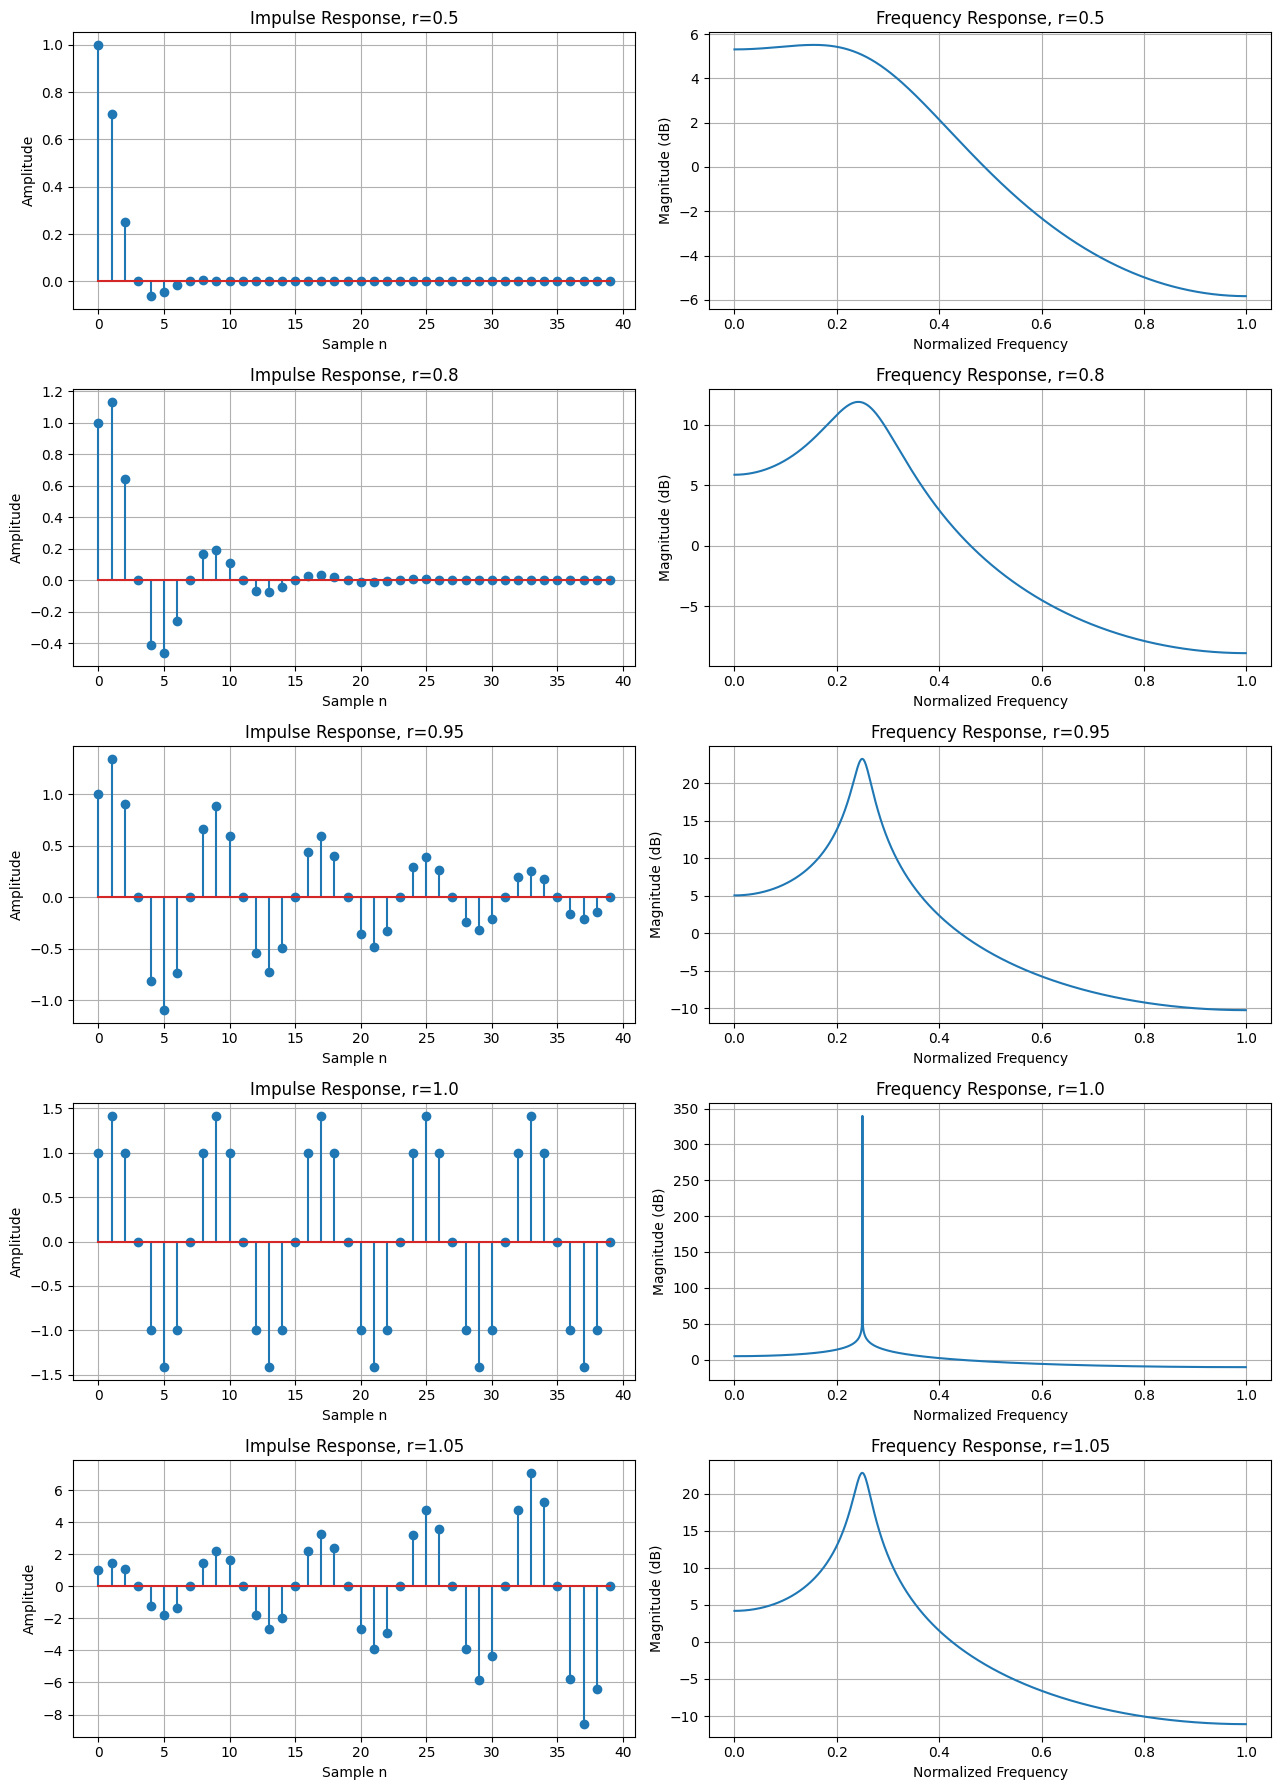

In [5]:
# ==========================================
# TASK 4.3: POLE POSITION AND IMPULSE RESPONSE
# ==========================================

# Different pole radius values
r_values = [0.5, 0.8, 0.95, 1.0, 1.05]

# Angle of poles
theta = np.pi / 4

# Create impulse signal
impulse = np.zeros(40)
impulse[0] = 1

# Create figure
fig, axes = plt.subplots(
    5, 2,
    figsize=(13, 18)
)

for i, r in enumerate(r_values):

    # Denominator coefficients
    a = [
        1,
        -2*r*np.cos(theta),
        r**2
    ]

    # Numerator
    b = [1]

    # Calculate impulse response
    h = signal.lfilter(
        b,
        a,
        impulse
    )

    # Calculate frequency response
    w, H = signal.freqz(
        b,
        a,
        worN=1024
    )

    # Plot impulse response
    axes[i, 0].stem(
        np.arange(40),
        h
    )

    axes[i, 0].set_title(
        f"Impulse Response, r={r}"
    )

    axes[i, 0].set_xlabel("Sample n")
    axes[i, 0].set_ylabel("Amplitude")
    axes[i, 0].grid()

    # Plot frequency response
    axes[i, 1].plot(
        w/np.pi,
        20*np.log10(
            np.maximum(np.abs(H), 1e-12)
        )
    )

    axes[i, 1].set_title(
        f"Frequency Response, r={r}"
    )

    axes[i, 1].set_xlabel("Normalized Frequency")
    axes[i, 1].set_ylabel("Magnitude (dB)")
    axes[i, 1].grid()

plt.tight_layout()
plt.show()


### Results and Discussion

The experiment demonstrates that the pole radius affects the impulse response and frequency response of a digital system.

For r = 0.5, the impulse response decays quickly because the poles are far inside the unit circle.

For r = 0.8, the response decays more slowly.

For r = 0.95, the response lasts longer and the resonance becomes sharper.

For r = 1.0, the poles lie exactly on the unit circle. The impulse response does not decay and the system is not BIBO stable.

For r = 1.05, the poles are outside the unit circle. The impulse response grows with time, indicating an unstable system.

Therefore, systems with pole magnitudes less than 1 are stable, while systems with poles outside the unit circle are unstable. A pole on the unit circle also prevents BIBO stability for this resonator.

## TASK 4.4 — Stability of Given Systems

### Objective

To classify different digital systems as stable or unstable using their pole positions and impulse responses.

### Given Systems

System A:

H1(z) = 1 / (1 - 1.6z^-1 + 0.89z^-2)

System B:

H2(z) = (1 + z^-1) / (1 - 2.5z^-1 + z^-2)

System C:

H3(z) = 1 / (1 + 0.5z^-1 - 0.5z^-2)

System D:

H4(z) = 1 - z^-4

### Procedure

1. Define the numerator and denominator coefficients of each system.
2. Use the zplane function to calculate poles and zeros.
3. Plot the pole-zero diagram for each system.
4. Determine whether all poles are inside the unit circle.
5. Calculate and plot the impulse response.
6. Classify each system as stable or unstable.



 H1
Zeros: []
Poles: [0.8+0.5j 0.8-0.5j]
Pole magnitudes: [0.94339811 0.94339811]
Stable: True

 H2
Zeros: [-1.]
Poles: [2.  0.5]
Pole magnitudes: [2.  0.5]
Stable: False

 H3
Zeros: []
Poles: [-1.   0.5]
Pole magnitudes: [1.  0.5]
Stable: False

 H4
Zeros: [-1.00000000e+00+0.j  8.32667268e-17+1.j  8.32667268e-17-1.j
  1.00000000e+00+0.j]
Poles: []
Pole magnitudes: []
Stable: True


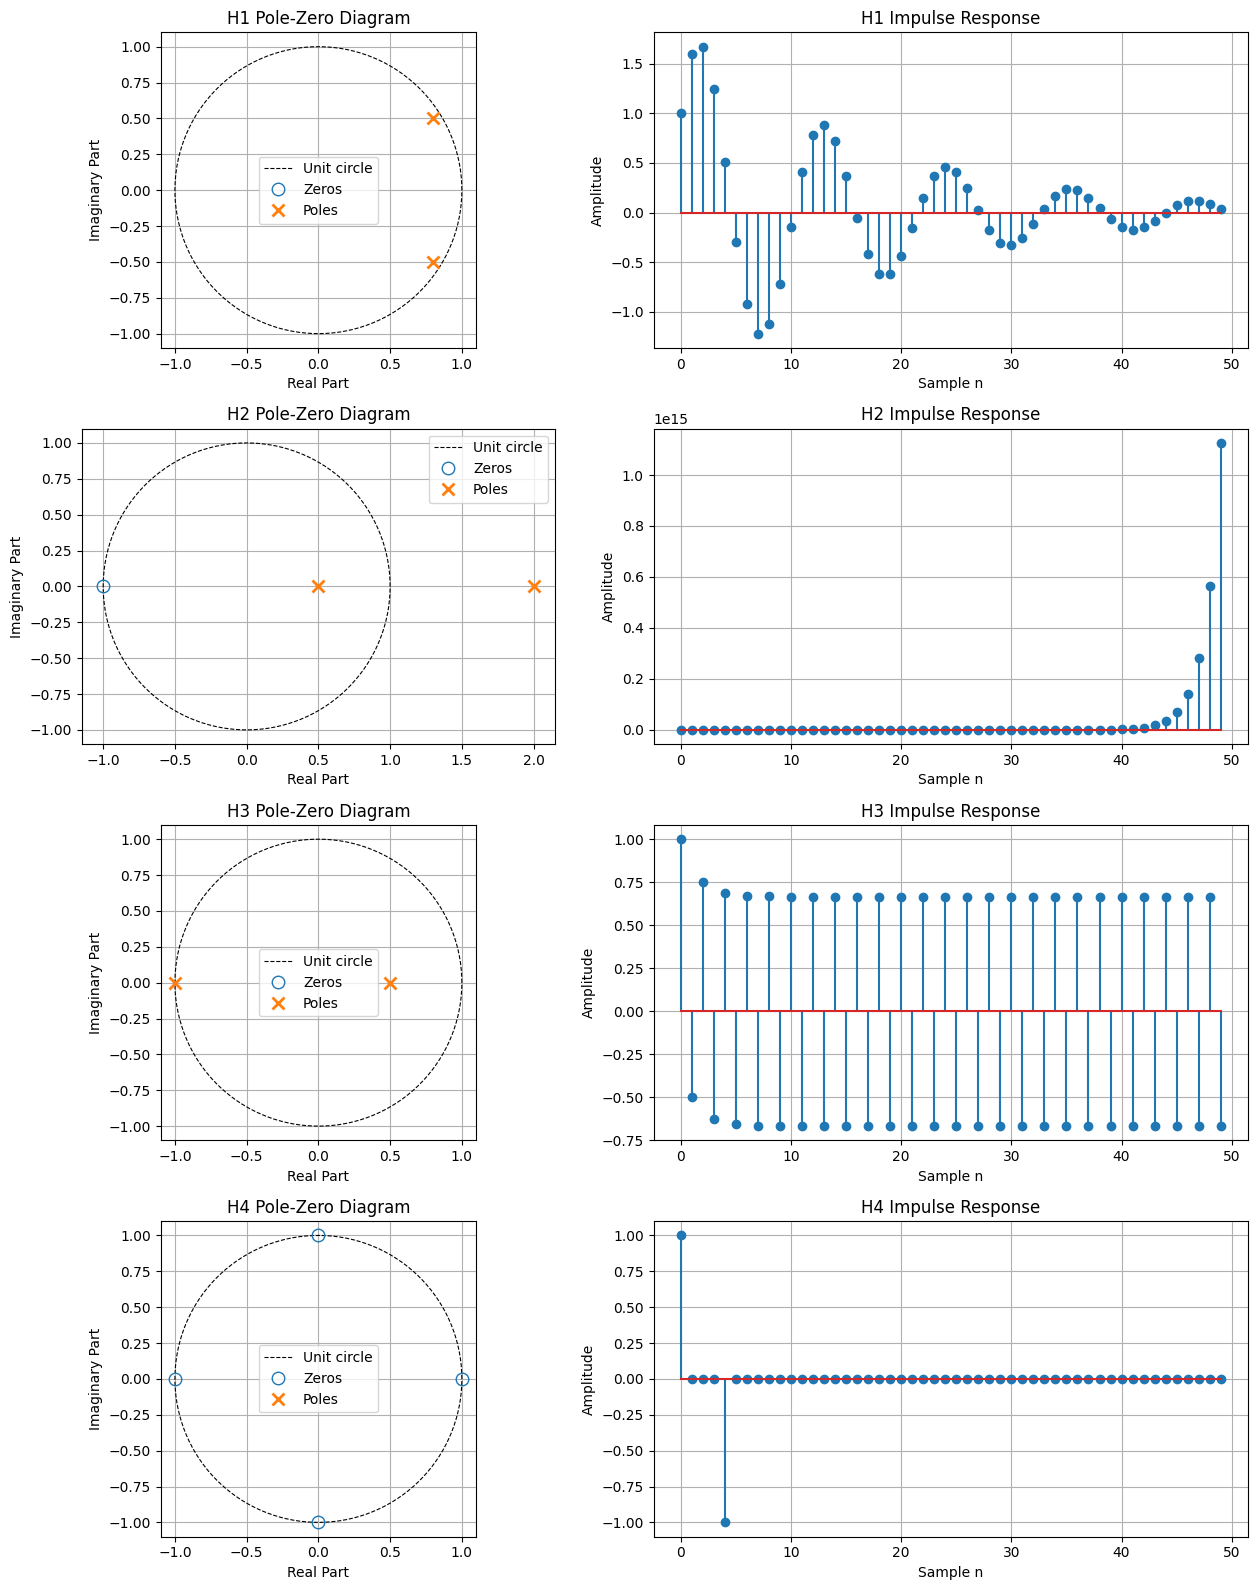

In [6]:
# ==========================================
# TASK 4.4: STABILITY OF GIVEN SYSTEMS
# ==========================================

systems = {
    "H1": {
        "b": [1],
        "a": [1, -1.6, 0.89]
    },

    "H2": {
        "b": [1, 1],
        "a": [1, -2.5, 1]
    },

    "H3": {
        "b": [1],
        "a": [1, 0.5, -0.5]
    },

    "H4": {
        "b": [1, 0, 0, 0, -1],
        "a": [1]
    }
}

# Generate impulse
impulse = np.zeros(50)
impulse[0] = 1

# Create plots
fig, axes = plt.subplots(
    4, 2,
    figsize=(13, 16)
)

for i, (name, system) in enumerate(systems.items()):

    b = system["b"]
    a = system["a"]

    # Calculate poles and zeros
    z, p, k = signal.tf2zpk(b, a)

    # Check stability
    stable = np.all(np.abs(p) < 1)

    # Calculate impulse response
    h = signal.lfilter(
        b,
        a,
        impulse
    )

    # Print results
    print("\n", name)
    print("Zeros:", z)
    print("Poles:", p)
    print("Pole magnitudes:", np.abs(p))
    print("Stable:", stable)

    # Plot pole-zero diagram
    zplane(b, a, axes[i, 0])

    axes[i, 0].set_title(
        f"{name} Pole-Zero Diagram"
    )

    # Plot impulse response
    axes[i, 1].stem(
        np.arange(len(h)),
        h
    )

    axes[i, 1].set_title(
        f"{name} Impulse Response"
    )

    axes[i, 1].set_xlabel("Sample n")
    axes[i, 1].set_ylabel("Amplitude")
    axes[i, 1].grid()

plt.tight_layout()
plt.show()

### Results and Discussion

The stability of each system is determined by examining the magnitudes of its poles.

**System H1:** Stable. Its poles are inside the unit circle.

**System H2:** Unstable. It has a pole outside the unit circle.

**System H3:** Unstable. One of its poles lies on the unit circle, while another lies inside it. A causal system with a pole on the unit circle is not BIBO stable.

**System H4:** Stable. It is an FIR system with a finite impulse response and no poles outside the unit circle.

The impulse response plots support the stability classification. Stable systems have bounded impulse responses, while unstable systems exhibit responses that do not decay appropriately.

## TASK 4.5 — Design a Resonator

### Objective

To design a second-order digital resonator that produces a peak at 1 kHz using a sampling frequency of 8 kHz.

### Design Specifications

- Resonance frequency = 1 kHz
- Sampling frequency = 8 kHz
- Pole radius r = 0.97
- Zeros at z = +1 and z = -1

### Background

A resonator is a digital filter designed to emphasize a particular frequency.

The pole positions determine the resonant frequency and bandwidth.

For this experiment, the poles are placed at an angle corresponding to 1 kHz, with a radius of 0.97.

Zeros are placed at +1 and -1 to block DC and the Nyquist frequency respectively.

White noise is used as the input signal to observe the resonator output.

### Procedure

1. Calculate the pole angle using the resonance frequency and sampling frequency.
2. Calculate the denominator coefficients.
3. Define zeros at +1 and -1.
4. Plot the pole-zero diagram.
5. Plot the frequency response in Hz.
6. Generate white noise.
7. Apply the resonator to the white noise using lfilter.
8. Listen to the output.

Numerator coefficients: [1, 0, -1]
Denominator coefficients: [1, np.float64(-1.3717871555019023), 0.9409]

Zeros: [-1.  1.]
Poles: [0.68589358+0.68589358j 0.68589358-0.68589358j]


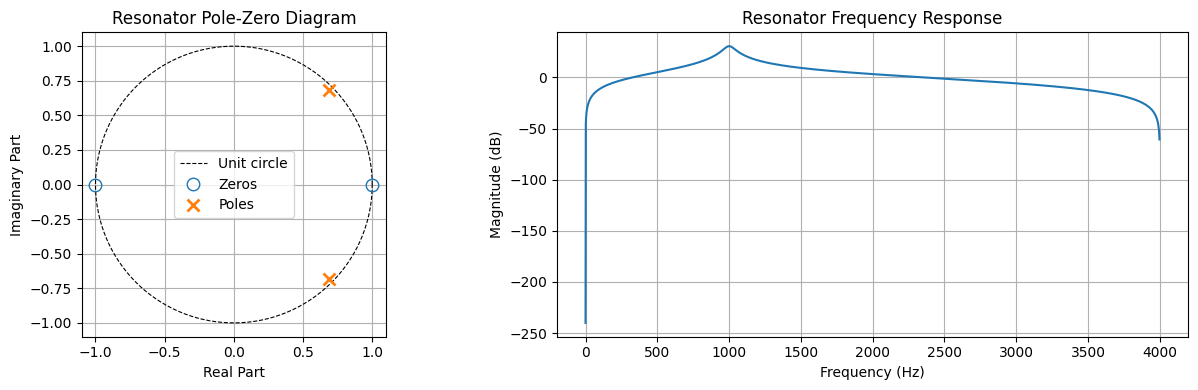

In [7]:
# ==========================================
# TASK 4.5: DESIGN A SECOND-ORDER RESONATOR
# ==========================================

# Design specifications
fs = 8000
f0 = 1000
r = 0.97

# Calculate pole angle
theta = 2*np.pi*f0/fs

# Numerator: zeros at +1 and -1
b = [1, 0, -1]

# Denominator: complex conjugate poles
a = [
    1,
    -2*r*np.cos(theta),
    r**2
]

print("Numerator coefficients:", b)
print("Denominator coefficients:", a)

# Calculate poles and zeros
z, p, k = signal.tf2zpk(b, a)

print("\nZeros:", z)
print("Poles:", p)

# Create plots
fig, (ax1, ax2) = plt.subplots(
    1, 2,
    figsize=(13, 4)
)

# Pole-zero diagram
zplane(b, a, ax1)

ax1.set_title("Resonator Pole-Zero Diagram")

# Frequency response
w, H = signal.freqz(
    b,
    a,
    worN=2048,
    fs=fs
)

ax2.plot(
    w,
    20*np.log10(
        np.maximum(np.abs(H), 1e-12)
    )
)

ax2.set_title("Resonator Frequency Response")
ax2.set_xlabel("Frequency (Hz)")
ax2.set_ylabel("Magnitude (dB)")
ax2.grid()

plt.tight_layout()
plt.show()

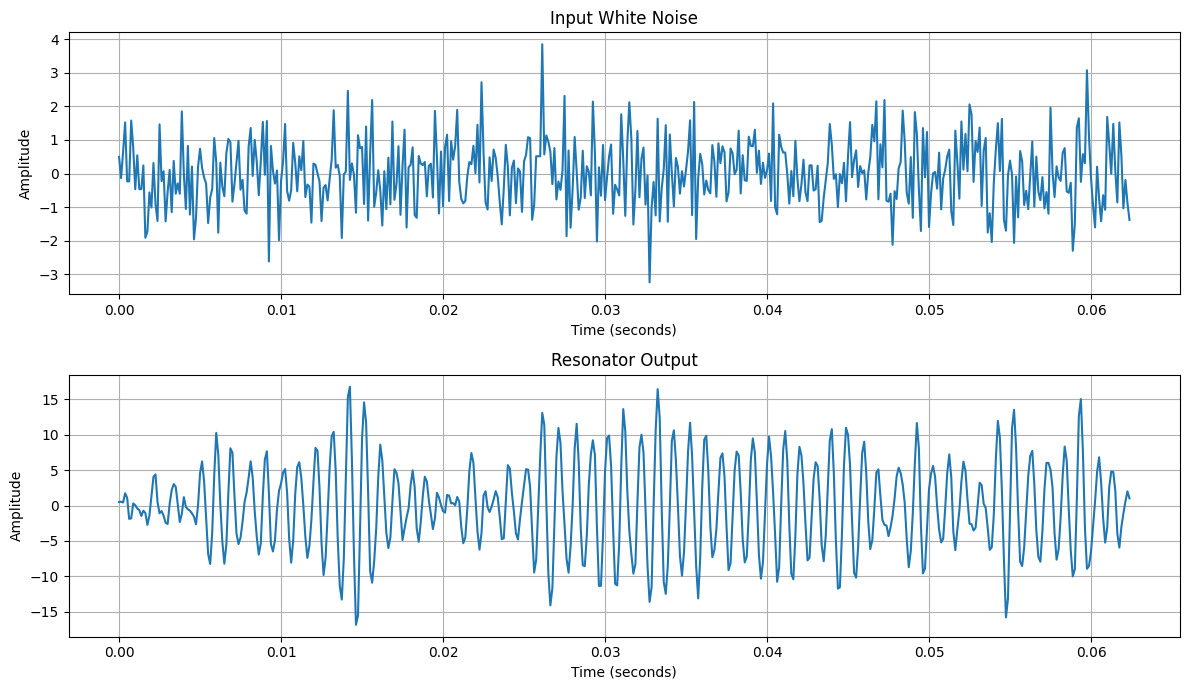

In [8]:
# ==========================================
# TASK 4.5: APPLY RESONATOR TO WHITE NOISE
# ==========================================

# Generate white noise
np.random.seed(42)

duration = 3

N = fs * duration

white_noise = np.random.randn(N)

# Apply resonator
y = signal.lfilter(
    b,
    a,
    white_noise
)

# Normalize output for listening
y_audio = y / np.max(np.abs(y))

# Create time axis
t = np.arange(N) / fs

# Plot input and output signals
fig, axes = plt.subplots(
    2, 1,
    figsize=(12, 7)
)

axes[0].plot(
    t[:500],
    white_noise[:500]
)

axes[0].set_title("Input White Noise")
axes[0].set_xlabel("Time (seconds)")
axes[0].set_ylabel("Amplitude")
axes[0].grid()

axes[1].plot(
    t[:500],
    y[:500]
)

axes[1].set_title("Resonator Output")
axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("Amplitude")
axes[1].grid()

plt.tight_layout()
plt.show()

# Listen to resonator output
display(
    Audio(y_audio, rate=fs)
)

### Observation

The designed resonator has a resonance frequency of approximately 1 kHz.

The pole-zero diagram shows that the poles are close to the unit circle, while the zeros are located at +1 and -1.

The frequency response shows a peak around the desired resonance frequency.

When white noise is passed through the resonator, the output emphasizes frequencies around 1 kHz.

The zeros at +1 and -1 reduce the response at DC and at the Nyquist frequency respectively.

The audio output demonstrates the frequency-selective behaviour of the resonator.

## CHECKPOINT 4

The checkpoint requires showing:

1. The stability classification of the four systems in Task 4.4.
2. The resonator frequency response from Task 4.5.

The stability classification is:

| System | Stability |
|---|---|
| H1 | Stable |
| H2 | Unstable |
| H3 | Unstable |
| H4 | Stable |

The resonator frequency response should show a peak around 1 kHz.

## ANALYSIS QUESTIONS

### Question 1

Explain the effect of r on the bandwidth of the resonance in Task 4.3.

**Answer:**

The value of r determines the distance of the poles from the origin.

When r is small, the resonance peak is wider and less sharp because the poles are far from the unit circle.

When r approaches 1, the resonance peak becomes narrower and sharper because the poles move closer to the unit circle.

Therefore, increasing r towards 1 reduces the bandwidth of the resonance and increases frequency selectivity.

### Question 2

What happens to h(n) when a pole lies exactly on the unit circle?

**Answer:**

When a pole lies exactly on the unit circle, the impulse response does not decay to zero.

For a complex pole pair on the unit circle, the impulse response produces sustained oscillations.

This means that the system is not BIBO stable because its impulse response is not absolutely summable.

### Question 3

Why does placing zeros at z = ±1 make the resonator a band-pass filter?

**Answer:**

A zero at z = +1 blocks the DC frequency, which is 0 Hz.

A zero at z = -1 blocks the Nyquist frequency, which is half the sampling frequency.

These zeros reduce the response at the low-frequency and high-frequency ends, while the poles create a peak around the selected resonant frequency.

Therefore, the resonator emphasizes a band of frequencies around 1 kHz and behaves like a band-pass filter.

### Question 4

Use the stability triangle (handout Example 2.4) to check your answers to Task 4.4 (a)-(c).

**Answer:**

For a second-order denominator of the form:

z² + a1z + a2

The stability conditions are:

1. The absolute value of a2 must be less than 1.
2. 1 + a1 + a2 must be greater than 0.
3. 1 - a1 + a2 must be greater than 0.

**System H1:**

a1 = -1.6 and a2 = 0.89

- |a2| = 0.89, which is less than 1.
- 1 + a1 + a2 = 0.29, which is greater than 0.
- 1 - a1 + a2 = 3.49, which is greater than 0.

All conditions are satisfied. Therefore, H1 is stable.

**System H2:**

a1 = -2.5 and a2 = 1

- |a2| = 1, which does not satisfy the strict condition.
- 1 + a1 + a2 = -0.5, which is less than 0.
- 1 - a1 + a2 = 4.5, which is greater than 0.

The conditions are not satisfied. Therefore, H2 is unstable.

**System H3:**

a1 = 0.5 and a2 = -0.5

- |a2| = 0.5, which is less than 1.
- 1 + a1 + a2 = 1, which is greater than 0.
- 1 - a1 + a2 = 0.

The third condition is on the boundary and is not strictly greater than zero.

Therefore, H3 is not BIBO stable.

### Conclusion

The stability triangle confirms the results obtained from the pole-zero diagrams.

H1 is stable, while H2 and H3 are unstable.

## CONCLUSION

This laboratory investigated the Z-transform, poles, zeros, inverse Z-transform and stability of digital systems.

The pole-zero plotting function was successfully implemented using SciPy. The inverse Z-transform was calculated using residuez and verified using lfilter.

The experiment also demonstrated that pole positions affect the impulse response and frequency response of a system. Poles inside the unit circle produce stable systems, while poles outside the unit circle produce unstable systems. Poles on the unit circle can also cause a system to become BIBO unstable.

Finally, a second-order resonator was designed with a resonance frequency of 1 kHz and applied to white noise. The frequency response demonstrated the ability of the resonator to emphasize a selected frequency.

The laboratory provided practical understanding of how poles and zeros are used in digital filter analysis and design.

## AI-USE STATEMENT

**AI tools used:** ChatGPT

**Used for:** Understanding Z-transform concepts, explaining programming errors, assisting with Python syntax and organizing the laboratory tasks.

**How I verified the output:** I executed the Python code in Google Colab, examined the generated pole-zero diagrams and frequency response plots, and compared the numerical results from residuez with those obtained using lfilter.

